# 4 · Article types: what kind of thing each article is

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed"
SEED = "Hundred Years' War"
BLUE, GRAY = "#2a78d6", "#b9b8b1"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

> ✏️ **[Your text]** Why add types? How were they made (hand labels on a random sample, a text classifier for the rest)?

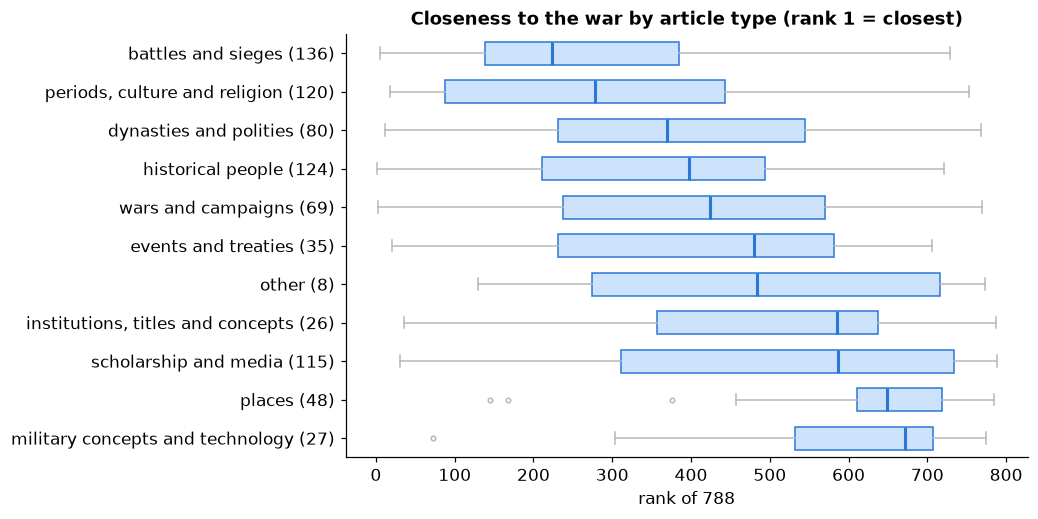

In [2]:
types = pd.read_parquet(DATA / "article_types.parquet").set_index("title")
seed = pd.read_parquet(DATA / "seed_similarity.parquet").set_index("title")
t = types.join(seed["milne_witten_rank"])
order = t.groupby("type")["milne_witten_rank"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([t.loc[t.type == k, "milne_witten_rank"] for k in order][::-1], orientation="horizontal", widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#cde2fb", "color": BLUE}, medianprops={"color": BLUE, "linewidth": 2},
           whiskerprops={"color": GRAY}, capprops={"color": GRAY}, flierprops={"markersize": 3, "markeredgecolor": GRAY})
ax.set_yticks(range(1, len(order) + 1), [f"{k} ({(t.type == k).sum()})" for k in order][::-1])
ax.set_title("Closeness to the war by article type (rank 1 = closest)")
ax.set_xlabel("rank of 788");

> ✏️ **[Your text]** Which kinds of articles sit closest to the war? Anything surprising (e.g. places)?

## Types vs themes (hand-labeled random sample only)

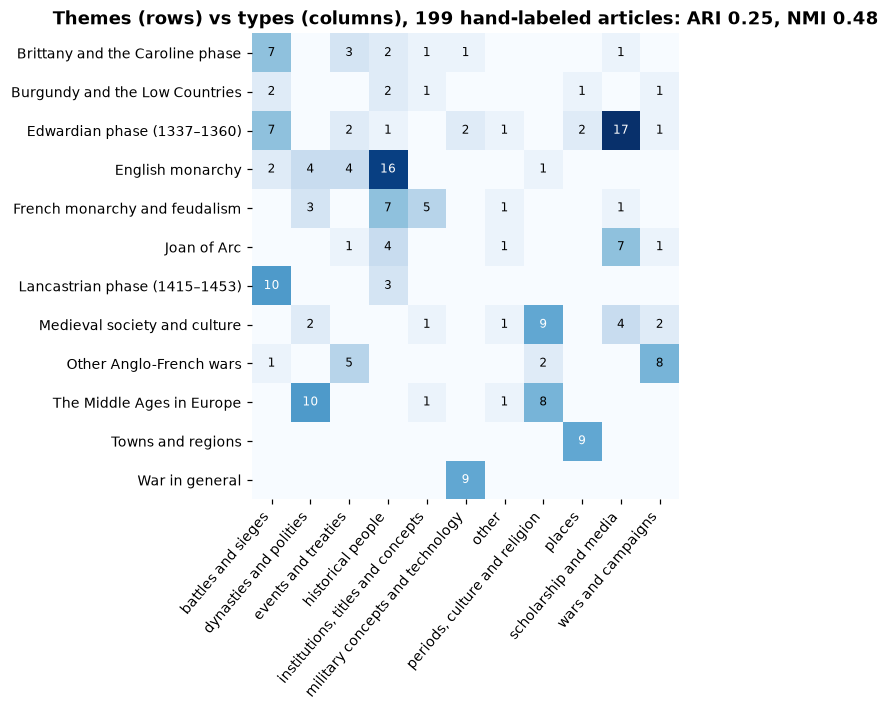

In [3]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

labels = pd.read_csv(ROOT / "data" / "labels" / "labels.csv").set_index("title")
sample = labels[labels["source"].fillna("").str.startswith("Amos")][["label"]]
sample = sample.join(pd.read_parquet(DATA / "clusters.parquet").set_index("title")["cluster_name"])
table = pd.crosstab(sample["cluster_name"], sample["label"])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.imshow(table, cmap="Blues")
ax.set_xticks(range(table.shape[1]), table.columns, rotation=50, ha="right", fontsize=9)
ax.set_yticks(range(table.shape[0]), table.index, fontsize=9)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        if table.iat[i, j]:
            ax.text(j, i, table.iat[i, j], ha="center", va="center", fontsize=8,
                    color="white" if table.iat[i, j] > table.values.max() / 2 else "black")
ari = adjusted_rand_score(sample["label"], sample["cluster_name"])
nmi = normalized_mutual_info_score(sample["label"], sample["cluster_name"])
ax.set_title(f"Themes (rows) vs types (columns), {len(sample)} hand-labeled articles: ARI {ari:.2f}, NMI {nmi:.2f}")
ax.spines[:].set_visible(False);

> ✏️ **[Your text]** Themes and types agree only partly. Why is that expected? (Links encode relatedness, text encodes similarity.)

**The classifier** (notebook 05): TF-IDF + logistic regression on each article's title, short description and first paragraph, never its links. Cross-validated on the random sample: macro-F1 0.67, accuracy 0.77 (always guessing the largest type: 0.18).

---
**Full analysis, with all the code:** [05_article_types.ipynb](https://github.com/amos-johnson/hundred-years-war-similarity/blob/main/notebooks/05_article_types.ipynb)